Explore. Carregue a base com o pandas, entenda as colunas e meça a proporção de fraudes;

In [1]:
import pandas as pd

url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'

df= pd.read_csv(url)

df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# Probelma de classificação desbalanceada
# Fraudes são raras -> modelo pode ignorar a classe 1

df['Class'].value_counts(normalize=True)# Calculando cada tipo de transação, 0 normal, 1 fraudes

,proportion
Class,
0,0.998273
1,0.001727


Prepare. Crie variáveis novas, como o log do valor, padronize com o StandardScaler e separe treino e teste com stratify, para manter a proporção de fraudes nos dois;

Criação de variaveis que ajudam o modelo


In [3]:
import numpy as np

df['Amount_log']= np.log1p(df['Amount'])


In [4]:
from sklearn.preprocessing import StandardScaler #transformar os dados para que tenha media igual a 0 e desvio padrão igual a 1, para terem os valores na mesma escala,

scaler= StandardScaler()
df['Amount_scaled']= scaler.fit_transform(df[['Amount']])

In [26]:
from os import X_OK
from sklearn.model_selection import train_test_split

X= df.drop('Class', axis=1) # features, todas as variaveis de entrada
y= df['Class'] #target, oque está querendo ver

X_train, X_test, y_train, y_test= train_test_split(# separar o modelo, dividir os dados em treino e teste. teste-> utilizado para avaliar o modelo 30% para teste no final, treino-> ensinar o modelo
    X, y, test_size=0.3, stratify=y, random_state=42
    )

Treine. Comece pela regressão logística como baseline e compare com Random Forest e XGBoost, usando o peso das classes e o ajuste do limiar de decisão;

In [33]:
from sklearn.linear_model import LogisticRegression #modelo de classificação, prever categoria, prever se é fraude class 1 ou não fraude class 0, serve baseline primeiro modelo pra inicar a analise

model= LogisticRegression(max_iter=1000)# 1000 interações
model.fit(X_train, y_train)#o modelo parende padrões a partir dos dados de treino; tenta encontrar as relações entre variaveis, features e o resultado fraude ou não fraude

y_pred= model.predict(X_test) # faz previsões nos modelos de teste

#Este modelo da um aviso, que informa que o não conseguiu terminar o processo dentro do numero de interações definido e não encontrou a melhor solução até a interação ser interrompida

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [37]:
#Utilizando o o Solver - saga utilizado para grande bases de dados, pois é mais rápido em conjuntos de dados grandes e lida melhor com o desbalanceamento de classes
from sklearn.linear_model import LogisticRegression

# Trocando o solver padrão para 'saga'
model = LogisticRegression(solver='saga', max_iter=1000)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [40]:
#utilizando o Solver- liblinear utilizado para bases de dados de pequenas e medias
from sklearn.linear_model import LogisticRegression

# Trocando o solver padrão para 'liblinear'
model = LogisticRegression(solver='liblinear', max_iter=1000)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


Avalie. Leia o relatório de classificação, a curva ROC e a curva de precisão e recall, com o recall da fraude como métrica principal;

In [41]:
from sklearn.metrics import classification_report #consegue ver as metricas mais importante para a classificação

print(classification_report(y_test, y_pred))

#precision -> Classificação do modelo
#recall -> identificação real do modelo
#f1-score -> media harmonica em precision e recall, visão geral da qualidade do modelo

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.81      0.56      0.66       148

    accuracy                           1.00     85443
   macro avg       0.91      0.78      0.83     85443
weighted avg       1.00      1.00      1.00     85443



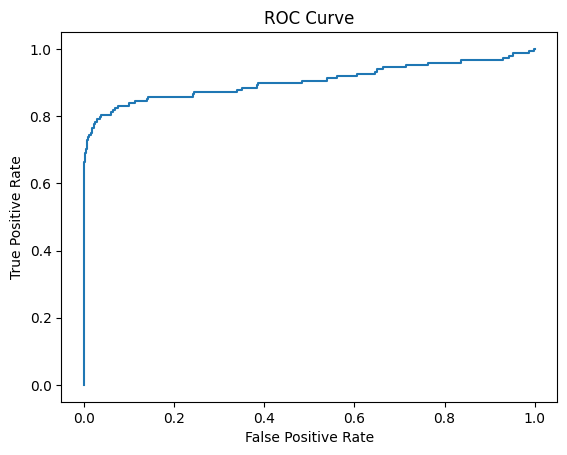

AUC: 0.9034356121758667


In [42]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

#curva ROC -> Metrica de modelo de classificação, mostra o desempenho do modelo em diferentes lineares de decisão
# quanto mais se aproxima do canto superior esquerdo melhor o modelo, siginifica alto recall e baixo erro; se fosse uma linha reta na diagonal o modelo seria aleatorio ou seja não teria capacidade de distinguir fraude de não fraude
y_probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.plot(fpr, tpr)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')#quantas transações nomais foram classificadas como fraude
plt.ylabel('True Positive Rate')#quantas fraudes o modelo conseguiu classificar, recall
plt.show()

print('AUC:', roc_auc_score(y_test, y_probs))

#AUC -> proximo de 1, indica um modelo muito bom; proximo 0,5 um mundo aleatorio

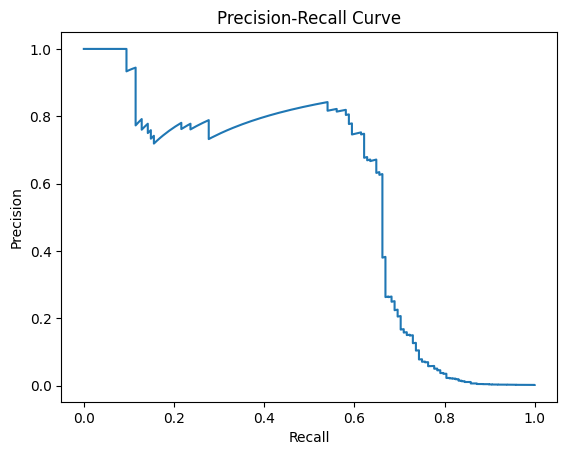

In [43]:
from sklearn.metrics import precision_recall_curve

#curva de precisão e recall -> utilizada muito com problemas de fraude desbalanceadas;
# monstra o tradeof entre as duas metricas;
#tradeof -> é é um equilibrio; quando se tenta aumentar o recall o precision diminuiu e vice-versa
#Em problemas desbalanceados como este, mostra o melhor comportamento do modelo do que a curva ROC
precision, recall, _ = precision_recall_curve(y_test, y_probs)

plt.plot(recall, precision)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')#quantas fraudes o modelo consegue identificar
plt.ylabel('Precision')#entre as transações classificadas como fraudes, quantas realmente são fraudes
plt.show()

#No inicio da curva a precision é super alta, siginifica que quanto o modelo é mais conservador e ele so aponta a fraude quando tem muito certeza, mas o recall é baixo ou seja, mnitas fraudes passam despercebidas.
# A medida que o recall aumenta, o modelo começa a identificar mais fraudes, porem a precisoan diminui, com isso aumenta o numero de falsos positivos
#no final quando o recall ta muito alto e o precision cai bastante isso seginifica que o modelo está marcando muitas transações como fraude.

Balanceamento de dados

In [10]:
#Undersampling

#pega todas as fraudes e depois seleciona a mesma quantidade de transações usando o sample
# ou seja es´ta reduzeindo a classe majoritaria, 0, para fica rdo mesmo tamanho da classe minoritaria,1.
# depois junta tudo
#reduz classe majoritaria
# perde muitos dadods normais, diminuindo a quantidade de dados para analise
fraudes = df[df['Class'] == 1]
normais = df[df['Class'] == 0].sample(n=len(fraudes), random_state=42)

df_under = pd.concat([fraudes, normais])

In [11]:
#Oversampling
#cria novos exemplos sistetidos da classe minoritaria,
#gera novas fraudes baseada, baseadas nas existentes,
#positivo não perde dados e aumenta a representação da classe fraude
#aumenta a classe minoritaria
#por outro lado está criando dados artificiais, então pode incluir ruidos
from imblearn.over_sampling import SMOTE

smote = SMOTE()
X_res, y_res = smote.fit_resample(X, y)

In [44]:
from sklearn.ensemble import RandomForestClassifier

#modelo mais sofisticado, modelo baseado em arvore de decisão
#conjunto de varias arvoes de decisão, cada arvore vai aparender um padrão diferente dos dados e no final o modelo vai combinar essad decisões, logo tende a ser mais preciso

rf= RandomForestClassifier(
    n_estimators=50, #escolhe uma quandidade de arvores
    max_depth=10, #profundidade da arvore tende a usar um valor baixo para evitar overfitting-> quando o modelode decora os dados de treino e na hora de tesstar ele não consegue classificar os novos dados
    class_weight='balanced',# ajustando automaticamente o peso da classes, no balanced da mais importancea para as classes minotitarios que são as fraudes, com isso ajuda o modelo a não ignorar essas ocorrencias que tende a ser mais raras
    n_jobs=-1,
    random_state=42)
rf.fit(X_train, y_train)

y_pred_rf= rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))



              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



In [20]:
from sklearn.ensemble import RandomForestClassifier

#modelo mais sofisticado, modelo baseado em arvore de decisão
#conjunto de varias arvoes de decisão, cada arvore vai aparender um padrão diferente dos dados e no final o modelo vai combinar essad decisões, logo tende a ser mais preciso

rf1= RandomForestClassifier(
    n_estimators=500, #escolhe uma quandidade de arvores
    max_depth=50, #profundidade da arvore tende a usar um valor baixo para evitar overfitting-> quando o modelode decora os dados de treino e na hora de tesstar ele não consegue classificar os novos dados
    class_weight='balanced',# ajustando automaticamente o peso da classes, no balanced da mais importancea para as classes minotitarios que são as fraudes, com isso ajuda o modelo a não ignorar essas ocorrencias que tende a ser mais raras
    n_jobs=-1,
    random_state=42)
rf1.fit(X_train, y_train)

y_pred_rf1= rf1.predict(X_test)

print(classification_report(y_test, y_pred_rf1))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.97      0.70      0.82       148

    accuracy                           1.00     85443
   macro avg       0.99      0.85      0.91     85443
weighted avg       1.00      1.00      1.00     85443



In [13]:
from sklearn.pipeline import Pipeline

#organizar o fluxo de processamento
#os dados passam primeiro pela padronização depois pelo modelo tudo num unico fluxo, evitando erro e garantindo consistencia
pipeline = Pipeline([
    ("scaler", StandardScaler()),#
    ("model", LogisticRegression(max_iter=1000))#
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

In [14]:
#por

threshold =0.3#padrão de 0.5, se a probabilidade de fraude for maior que 0.5 ele classifica como fraude

y_pred_cust = (y_probs > threshold).astype(int)

print(classification_report(y_test, y_pred_cust))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.79      0.71      0.75       148

    accuracy                           1.00     85443
   macro avg       0.89      0.85      0.87     85443
weighted avg       1.00      1.00      1.00     85443



## Mdelo Avançado - XGBoost
 É um dos algoritmos mais udados em competições de mercado
 Ele é mais poderoso que o RandomForest para muitos problemas

In [15]:
from  xgboost import XGBClassifier

#baseado em boost, uma tecnica em que varios modelos simples , são treinados em sequencia e cada novo modelo tenta corrigir os erros de cada modelo(arvore) anterior,
# diferente do Forest,  aqui tem umn aprendizado sequencial, as proximas arvores tentam corrigir os erros dos anteriores
#
xgb = XGBClassifier(
    scale_pos_weight=10, #ajuda com desbalanceamento
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [10:48:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [16]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



In [45]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Configuração focada em regularização pesada e precisão das decisões
xgb_precision = XGBClassifier(
    scale_pos_weight=10,       # Mantém o peso original equilibrado
    max_depth=6,
    learning_rate=0.1,
    gamma=2,                   # Punição para árvores que não reduzem o erro drasticamente
    subsample=0.8,             # Treina cada árvore com apenas 80% das linhas (evita decoreba)
    colsample_bytree=0.8,      # Usa apenas 80% das colunas por árvore
    eval_metric='logloss'
)

xgb_precision.fit(X_train, y_train)
y_pred_precision = xgb_precision.predict(X_test)


print(classification_report(y_test, y_pred_precision))


--- RESULTADO FOCADO EM PRECISÃO / REGULARIZAÇÃO ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.89      0.79      0.84       148

    accuracy                           1.00     85443
   macro avg       0.94      0.90      0.92     85443
weighted avg       1.00      1.00      1.00     85443



Explique. Veja a importância das variáveis e use o SHAP para mostrar o que pesou em cada decisão.

Importância das variaveis

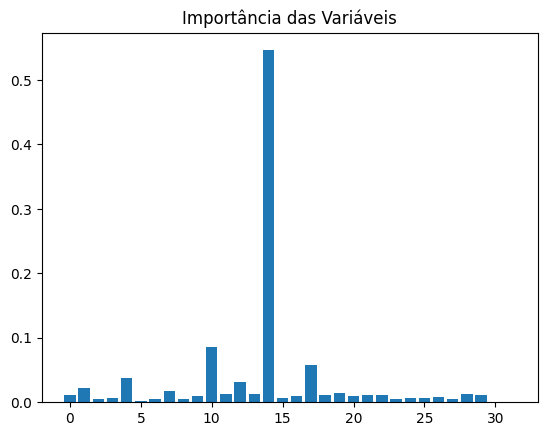

In [17]:
import matplotlib.pyplot as plt

importancias = xgb.feature_importances_

plt.bar(range(len(importancias)), importancias)
plt.title('Importância das Variáveis')
plt.show()

#mostrar a importancia de quanto cada variavem vai contribuir para as decisões dos modelos

Ajustes de hiperparametros

In [18]:
from sklearn.model_selection import GridSearchCV #testa automaticamente varias combinaç~eos de parametros e encontra a melhor

#testa varias combinações para tentar melhorar o modelo


param_grid={
    "max_depth": [3, 5],
    "n_estimators": [50,100],
}#conjunto de conbinaç~eos que se quer testar

grid = GridSearchCV(
    XGBClassifier(eval_metric='logloss'),
    param_grid,
    scoring= "recall",
    cv=3) # treina vairios modelos, cada um em uma conbinação diferente de parametors para avaliar o melhor
    #o melhor é o recall para se testar para esse modelo

grid.fit(X_train, y_train)

print("Melhor Modelo:", grid.best_params_)

Melhor Modelo: {'max_depth': 5, 'n_estimators': 100}


Explicabilidade (SHAP)
SHAP -> mostra como cada variavel influencia a decisão do modelo

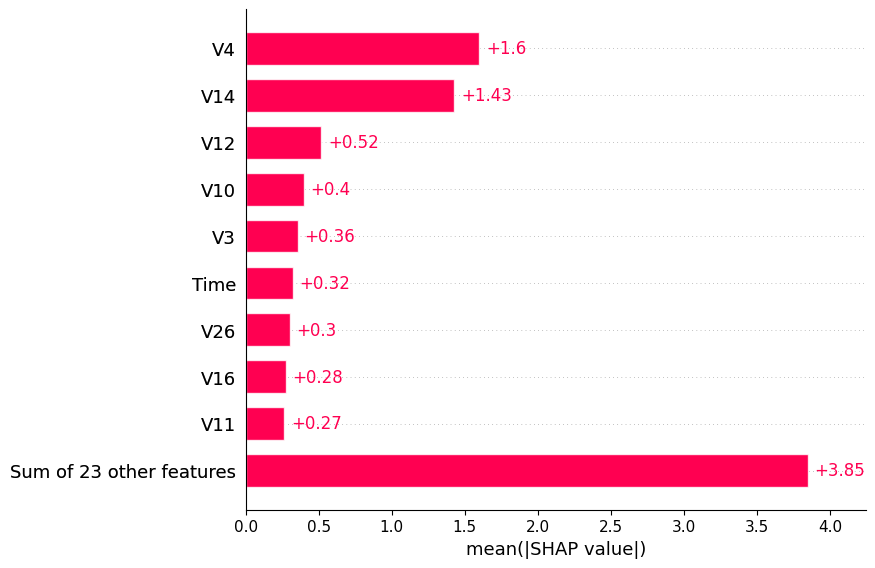

In [19]:
import shap

#é um tecinica que vai esplica como cada variavel contribui para a decisão do modelo, monstra o impacto de cada variavel na decisão
# quanto maior o valor mais influencia o modelo
#vai permitir entender o modelo mesmo sendo mais complexo
#usado para entender quais variais levaram a desição se era fraude ou não

explainer = shap.Explainer(xgb)
shap_values = explainer(X_test[:100])

shap.plots.bar(shap_values)